In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
from PIL import Image
import os, json
import numpy as np
import pandas as pd
from scipy import ndimage
import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


# ResNet34-U-Net with boundary-guided attention

Same boundary head as the other notebook, plus a gate: the predicted boundary map reweights the full-resolution decoder features before the segmentation head (`d0 + scale * d0 * sigmoid(boundary)`, with `scale` initialised to 0 so training starts from the baseline). Total loss = BCE + Dice + 0.2 x boundary loss.

**Logged identically in all three notebooks** (so results are directly comparable):

* every epoch: train/validation total loss, segmentation loss and boundary loss, IoU, Dice, precision, recall, F1, accuracy, boundary F1 of the predicted *mask* (2 px tolerance) and, where a head exists, of the head output, plus the learning rate;
* every epoch: `history_<tag>.csv` is rewritten, the **last** checkpoint is overwritten and the **best** checkpoint is updated when the validation **segmentation** loss improves (the boundary term is excluded from the selection, so all three models are chosen by the same rule);
* early stopping on the same quantity, patience 10, up to 200 epochs;
* at the end: test (and validation) metrics, per-image IoU, **fragment counts** (connected panel regions in prediction vs ground truth), a confusion matrix, and `results_<tag>.json` / `per_image_test_<tag>.csv`.

Settings: batch 5, lr 2e-4, AdamW, up to **200 epochs, early-stopping patience 10**, no random seed is set.

In [2]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch, dropout_rate=0.15, use_dropout=True):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        ]
        if use_dropout:
            layers.append(nn.Dropout2d(dropout_rate))

        layers.extend([
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        ])
        if use_dropout:
            layers.append(nn.Dropout2d(dropout_rate))

        self.double_conv = nn.Sequential(*layers)

    def forward(self, x):
        return self.double_conv(x)

# (constructor, ImageNet weights enum name, channels of [stem, layer1, layer2, layer3, layer4])
RESNET_CFG = {
    'resnet18':  (models.resnet18,  'ResNet18_Weights',  [64, 64, 128, 256, 512]),
    'resnet34':  (models.resnet34,  'ResNet34_Weights',  [64, 64, 128, 256, 512]),
    'resnet50':  (models.resnet50,  'ResNet50_Weights',  [64, 256, 512, 1024, 2048]),
    'resnet101': (models.resnet101, 'ResNet101_Weights', [64, 256, 512, 1024, 2048]),
}

class ResNetUNet(nn.Module):
    """U-Net with a ResNet encoder.

    Encoder (strides relative to the input):
        stem   (conv7x7 + BN + ReLU)  /2
        layer1 (after maxpool)        /4
        layer2                        /8
        layer3                        /16
        layer4 (bottleneck)           /32
    Decoder: ConvTranspose2d x2 + skip concat + DoubleConv, five times, back to full resolution.
    Input height/width must be divisible by 32 (256x256 is fine).
    """
    def __init__(self, backbone='resnet34', pretrained=True, in_ch=3, out_ch=1,
                 dropout_rates=None):
        super().__init__()
        if backbone not in RESNET_CFG:
            raise ValueError(f"backbone must be one of {list(RESNET_CFG)}")

        if dropout_rates is None:
            dropout_rates = {
                'encoder': {'layer3': 0.15, 'layer4': 0.2},   # same idea as U-Net: enc4 = 0.15, bottleneck = 0.2
                'decoder': 0.15,
            }
        self.dropout_rates = dropout_rates

        ctor, weights_name, ch = RESNET_CFG[backbone]
        weights = getattr(models, weights_name).IMAGENET1K_V1 if pretrained else None
        backbone_net = ctor(weights=weights)

        # Optional: support in_ch != 3 by rebuilding the first conv
        if in_ch != 3:
            backbone_net.conv1 = nn.Conv2d(in_ch, 64, kernel_size=7, stride=2, padding=3, bias=False)

        # Encoder
        self.stem = nn.Sequential(backbone_net.conv1, backbone_net.bn1, backbone_net.relu)  # /2
        self.pool = backbone_net.maxpool                                                    # /4
        self.layer1 = backbone_net.layer1
        self.layer2 = backbone_net.layer2
        self.layer3 = backbone_net.layer3
        self.layer4 = backbone_net.layer4

        self.drop3 = nn.Dropout2d(dropout_rates['encoder']['layer3'])
        self.drop4 = nn.Dropout2d(dropout_rates['encoder']['layer4'])

        c0, c1, c2, c3, c4 = ch
        d = dropout_rates['decoder']

        # Decoder
        self.up4 = nn.ConvTranspose2d(c4, c3, kernel_size=2, stride=2)       # /32 -> /16
        self.dec4 = DoubleConv(c3 * 2, c3, d, use_dropout=True)
        self.up3 = nn.ConvTranspose2d(c3, c2, kernel_size=2, stride=2)       # /16 -> /8
        self.dec3 = DoubleConv(c2 * 2, c2, d, use_dropout=True)
        self.up2 = nn.ConvTranspose2d(c2, c1, kernel_size=2, stride=2)       # /8  -> /4
        self.dec2 = DoubleConv(c1 * 2, c1, d, use_dropout=True)
        self.up1 = nn.ConvTranspose2d(c1, c0, kernel_size=2, stride=2)       # /4  -> /2
        self.dec1 = DoubleConv(c0 * 2, c0, d, use_dropout=True)
        self.up0 = nn.ConvTranspose2d(c0, 32, kernel_size=2, stride=2)       # /2  -> full res
        self.dec0 = DoubleConv(32, 32, d, use_dropout=True)

        self.final_conv = nn.Conv2d(32, out_ch, kernel_size=1)
        self.boundary_feature = nn.Sequential(
            nn.Conv2d(32, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
        )
        self.boundary_head = nn.Conv2d(16, out_ch, kernel_size=1)
        self.boundary_attention_scale = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        # Encoder
        e0 = self.stem(x)                       # /2
        e1 = self.layer1(self.pool(e0))         # /4
        e2 = self.layer2(e1)                    # /8
        e3 = self.drop3(self.layer3(e2))        # /16
        b = self.drop4(self.layer4(e3))         # /32 (bottleneck)

        # Decoder
        d4 = self.dec4(torch.cat([self.up4(b), e3], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e2], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e1], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e0], dim=1))
        d0 = self.dec0(self.up0(d1))

        boundary_features = self.boundary_feature(d0)
        boundary_logits = self.boundary_head(boundary_features)
        boundary_attention = torch.sigmoid(boundary_logits)
        refined_features = d0 + self.boundary_attention_scale * (d0 * boundary_attention)
        segmentation_logits = self.final_conv(refined_features)
        return segmentation_logits, boundary_logits

## Dataset and Data Loading

In [3]:
IMG_EXTS = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')

class SegDataset(Dataset):
    """Reads from a pre-made split folder that already contains 'img/' and 'mask/'
    subfolders (e.g. root_dir/train/Img, root_dir/train/Masks). Mask files are named
    '<stem>_mask.<ext>' (folder-name case is ignored)."""
    def __init__(self, root_dir, split='train', transform=None, img_size=(256, 256)):
        self.root_dir = root_dir
        self.split = split
        self.img_size = img_size
        self.transform = transform

        split_dir = os.path.join(root_dir, split)
        # case-insensitive lookup so 'Img' / 'img' and 'Masks' / 'masks' all work
        def _sub(name):
            for d in os.listdir(split_dir):
                if d.lower() == name:
                    return os.path.join(split_dir, d)
            raise FileNotFoundError(f"'{name}' folder not found in {split_dir}: {os.listdir(split_dir)}")
        self.img_dir = _sub('img')
        self.mask_dir = _sub('masks')

        mask_stems = {os.path.splitext(f)[0].replace('_mask', ''): f
                      for f in os.listdir(self.mask_dir) if f.lower().endswith(IMG_EXTS)}

        self.pairs = []
        for f in sorted(os.listdir(self.img_dir)):
            if not f.lower().endswith(IMG_EXTS):
                continue
            stem = os.path.splitext(f)[0]
            if stem in mask_stems:
                self.pairs.append((f, mask_stems[stem]))

        assert len(self.pairs) > 0, f"No image/mask pairs found under {split_dir}"

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_name, mask_name = self.pairs[idx]

        img = Image.open(os.path.join(self.img_dir, img_name)).convert('RGB')
        label = Image.open(os.path.join(self.mask_dir, mask_name)).convert('L')

        img = img.resize(self.img_size)
        label = label.resize(self.img_size, Image.NEAREST)

        if self.transform:
            img = self.transform(img)
        else:
            img = transforms.ToTensor()(img)

        label = torch.from_numpy((np.array(label) > 0).astype(np.float32)).unsqueeze(0)

        return img, label

## Losses and metrics

Segmentation loss is your original 0.6 BCE + 0.4 Dice. The boundary target is a ~2 px band from a 3x3 dilation-minus-erosion of the mask. Boundary F1 uses a 2 px matching tolerance. Fragment count = number of 8-connected regions of at least 16 pixels.

In [4]:
# ===================== losses =====================
def dice_loss_from_logits(logits, target, smooth=1e-6):
    probs = torch.sigmoid(logits)
    intersection = (probs * target).sum(dim=(2, 3))
    denom = probs.sum(dim=(2, 3)) + target.sum(dim=(2, 3))
    return 1.0 - ((2.0 * intersection + smooth) / (denom + smooth)).mean()


def boundary_target_from_mask(mask):
    """~2 px wide boundary band (dilation minus erosion with a 3x3 window) from a binary mask."""
    dilated = F.max_pool2d(mask, kernel_size=3, stride=1, padding=1)
    eroded = 1.0 - F.max_pool2d(1.0 - mask, kernel_size=3, stride=1, padding=1)
    return (dilated - eroded).clamp(0.0, 1.0)


def seg_loss_fn(seg_logits, mask):
    """Same segmentation loss as your baseline: 0.6 * BCE + 0.4 * Dice."""
    bce = nn.BCEWithLogitsLoss()(seg_logits, mask)
    return 0.6 * bce + 0.4 * dice_loss_from_logits(seg_logits, mask)


def boundary_loss_fn(boundary_logits, mask):
    target = boundary_target_from_mask(mask)
    positives = target.sum()
    negatives = target.numel() - positives
    pos_weight = (negatives / positives.clamp_min(1.0)).clamp(min=1.0, max=20.0).reshape(1)
    bce = F.binary_cross_entropy_with_logits(boundary_logits, target, pos_weight=pos_weight)
    return 0.5 * bce + 0.5 * dice_loss_from_logits(boundary_logits, target)


def combined_loss(seg_logits, boundary_logits, mask, boundary_weight=0.2):
    """Returns (total, segmentation part, boundary part). Baseline (no boundary branch): total == segmentation."""
    seg = seg_loss_fn(seg_logits, mask)
    if boundary_logits is None:
        return seg, seg.detach(), torch.zeros((), device=seg.device)
    bnd = boundary_loss_fn(boundary_logits, mask)
    return seg + boundary_weight * bnd, seg.detach(), bnd.detach()


# ===================== pixel metrics =====================
def confusion_counts(logits, masks, thresh=0.5):
    pred = torch.sigmoid(logits) >= thresh
    target = masks >= 0.5
    return {'tn': int(torch.logical_and(~pred, ~target).sum().item()),
            'fp': int(torch.logical_and(pred, ~target).sum().item()),
            'fn': int(torch.logical_and(~pred, target).sum().item()),
            'tp': int(torch.logical_and(pred, target).sum().item())}


def metrics_from_counts(counts):
    tn, fp, fn, tp = (counts[k] for k in ('tn', 'fp', 'fn', 'tp'))
    eps = 1e-8
    iou = tp / (tp + fp + fn + eps)
    dice = (2 * tp) / (2 * tp + fp + fn + eps)
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)
    accuracy = (tp + tn) / (tp + tn + fp + fn + eps)
    iou_bg = tn / (tn + fp + fn + eps)
    return {'iou': iou, 'miou': (iou_bg + iou) / 2, 'dice': dice, 'precision': precision,
            'recall': recall, 'f1': f1, 'acc': accuracy}


# ===================== boundary metrics (2 px tolerance) =====================
def edge_match_counts(pred_edge, true_edge, tolerance=2):
    k = 2 * tolerance + 1
    pred_near_true = pred_edge * F.max_pool2d(true_edge, kernel_size=k, stride=1, padding=tolerance)
    true_near_pred = true_edge * F.max_pool2d(pred_edge, kernel_size=k, stride=1, padding=tolerance)
    return {'pred_matched': float(pred_near_true.sum().item()), 'true_matched': float(true_near_pred.sum().item()),
            'pred_total': float(pred_edge.sum().item()), 'true_total': float(true_edge.sum().item())}


@torch.no_grad()
def mask_edge_counts(seg_logits, masks, tolerance=2, thresh=0.5):
    """Boundary quality of the SEGMENTATION MASK itself -> defined for every model, including the baseline."""
    pred_mask = (torch.sigmoid(seg_logits) >= thresh).float()
    return edge_match_counts(boundary_target_from_mask(pred_mask), boundary_target_from_mask(masks), tolerance)


@torch.no_grad()
def head_edge_counts(boundary_logits, masks, tolerance=2, thresh=0.5):
    """Quality of the boundary head's own output (only for models that have a head)."""
    pred_edge = (torch.sigmoid(boundary_logits) >= thresh).float()
    return edge_match_counts(pred_edge, boundary_target_from_mask(masks), tolerance)


def edge_metrics_from_counts(c):
    eps = 1e-8
    p = c['pred_matched'] / (c['pred_total'] + eps)
    r = c['true_matched'] / (c['true_total'] + eps)
    return p, r, 2 * p * r / (p + r + eps)


# ===================== fragment count (per image) =====================
def count_components(binary, min_area=16):
    """Number of 8-connected foreground regions with at least min_area pixels."""
    labeled, n = ndimage.label(binary, structure=np.ones((3, 3)))
    if n == 0:
        return 0
    areas = np.bincount(labeled.ravel())[1:]
    return int((areas >= min_area).sum())


@torch.no_grad()
def per_image_report(model, dataset, thresh=0.5, min_area=16):
    """Per-image IoU and number of connected panel regions in prediction vs ground truth."""
    model.eval()
    rows = []
    for idx in range(len(dataset)):
        img, gt = dataset[idx]
        seg_logits, _ = model(img.unsqueeze(0).to(device))
        pred = (torch.sigmoid(seg_logits)[0, 0].cpu() >= thresh).numpy().astype(np.uint8)
        g = (gt[0].numpy() >= 0.5).astype(np.uint8)
        inter = int((pred & g).sum()); union = int((pred | g).sum())
        rows.append({'image': idx, 'iou': inter / union if union > 0 else np.nan,
                     'pred_fragments': count_components(pred, min_area),
                     'gt_fragments': count_components(g, min_area),
                     'pred_px': int(pred.sum()), 'gt_px': int(g.sum())})
    return pd.DataFrame(rows)


def fragment_summary(df):
    diff = df['pred_fragments'] - df['gt_fragments']
    return {'mean_image_iou': float(df['iou'].mean()),
            'mean_pred_fragments': float(df['pred_fragments'].mean()),
            'mean_gt_fragments': float(df['gt_fragments'].mean()),
            'mean_abs_fragment_error': float(diff.abs().mean()),
            'frac_images_over_fragmented': float((diff > 0).mean())}

## Training and validation functions

In [5]:
import copy

class EarlyStopping:
    """Stops when the monitored loss has not improved for `patience` epochs; restores the best weights."""
    def __init__(self, patience=10, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = None
        self.counter = 0
        self.best_weights = None

    def __call__(self, val_loss, model):
        if self.best_loss is None or self.best_loss - val_loss > self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_weights = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
        if self.counter >= self.patience:
            if self.best_weights is not None:
                model.load_state_dict(self.best_weights)
            return True
        return False


def train_one_epoch(model, loader, optimizer):
    model.train()
    running = {'total': 0.0, 'seg': 0.0, 'boundary': 0.0}
    counts = {'tn': 0, 'fp': 0, 'fn': 0, 'tp': 0}
    for imgs, masks in tqdm(loader, desc='Train batch', leave=False):
        imgs, masks = imgs.to(device), masks.to(device)
        optimizer.zero_grad(set_to_none=True)
        seg_logits, boundary_logits = model(imgs)
        loss, seg_loss, boundary_loss = combined_loss(seg_logits, boundary_logits, masks)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        bs = imgs.size(0)
        running['total'] += loss.item() * bs
        running['seg'] += seg_loss.item() * bs
        running['boundary'] += boundary_loss.item() * bs
        bc = confusion_counts(seg_logits.detach(), masks)
        for k in counts:
            counts[k] += bc[k]
    n = len(loader.dataset)
    return {k: v / n for k, v in running.items()}, metrics_from_counts(counts)


@torch.no_grad()
def validate(model, loader):
    """Identical for every notebook: losses, pixel metrics, mask-edge F1 and (if present) head-edge F1."""
    model.eval()
    running = {'total': 0.0, 'seg': 0.0, 'boundary': 0.0}
    counts = {'tn': 0, 'fp': 0, 'fn': 0, 'tp': 0}
    mask_edges = {'pred_matched': 0.0, 'true_matched': 0.0, 'pred_total': 0.0, 'true_total': 0.0}
    head_edges = dict(mask_edges)
    has_head = False
    for imgs, masks in tqdm(loader, desc='Val batch', leave=False):
        imgs, masks = imgs.to(device), masks.to(device)
        seg_logits, boundary_logits = model(imgs)
        loss, seg_loss, boundary_loss = combined_loss(seg_logits, boundary_logits, masks)
        bs = imgs.size(0)
        running['total'] += loss.item() * bs
        running['seg'] += seg_loss.item() * bs
        running['boundary'] += boundary_loss.item() * bs
        bc = confusion_counts(seg_logits, masks)
        for k in counts:
            counts[k] += bc[k]
        me = mask_edge_counts(seg_logits, masks)
        for k in mask_edges:
            mask_edges[k] += me[k]
        if boundary_logits is not None:
            has_head = True
            he = head_edge_counts(boundary_logits, masks)
            for k in head_edges:
                head_edges[k] += he[k]
    n = len(loader.dataset)
    mp, mr, mf = edge_metrics_from_counts(mask_edges)
    if has_head:
        hp, hr, hf = edge_metrics_from_counts(head_edges)
    else:
        hp = hr = hf = float('nan')
    return {'loss': running['total'] / n, 'seg_loss': running['seg'] / n, 'boundary_loss': running['boundary'] / n,
            **metrics_from_counts(counts),
            'mask_edge_precision': mp, 'mask_edge_recall': mr, 'mask_edge_f1': mf,
            'head_edge_precision': hp, 'head_edge_recall': hr, 'head_edge_f1': hf,
            'confusion': np.array([[counts['tn'], counts['fp']], [counts['fn'], counts['tp']]])}


def train_model(model, train_loader, val_loader, num_epochs=200, learning_rate=2e-4, patience=10,
                ckpt_path='best.pth', last_path='last.pth', history_csv='history.csv'):
    """Every epoch: validate, log, write history CSV, save the 'last' checkpoint, and update the 'best'
    checkpoint when the validation SEGMENTATION loss improves (same selection rule in all notebooks)."""
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (no_decay if (p.ndim == 1 or name.endswith('.bias')) else decay).append(p)
    optimizer = optim.AdamW([{'params': decay, 'weight_decay': 1e-2},
                             {'params': no_decay, 'weight_decay': 0.0}], lr=learning_rate)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.7, patience=7, min_lr=1e-6)
    early_stopping = EarlyStopping(patience=patience, min_delta=1e-4)

    rows, best_val, best_epoch = [], float('inf'), 0
    for epoch in range(num_epochs):
        lr = optimizer.param_groups[0]['lr']
        tr_loss, tr_m = train_one_epoch(model, train_loader, optimizer)
        v = validate(model, val_loader)
        scheduler.step(v['seg_loss'])

        rows.append({'epoch': epoch + 1, 'lr': lr,
                     'train_loss': tr_loss['total'], 'train_seg_loss': tr_loss['seg'],
                     'train_boundary_loss': tr_loss['boundary'], 'train_acc': tr_m['acc'], 'train_iou': tr_m['iou'],
                     'val_loss': v['loss'], 'val_seg_loss': v['seg_loss'], 'val_boundary_loss': v['boundary_loss'],
                     'val_iou': v['iou'], 'val_dice': v['dice'], 'val_precision': v['precision'],
                     'val_recall': v['recall'], 'val_f1': v['f1'], 'val_acc': v['acc'],
                     'val_mask_edge_f1': v['mask_edge_f1'], 'val_head_edge_f1': v['head_edge_f1']})
        pd.DataFrame(rows).to_csv(history_csv, index=False)

        improved = v['seg_loss'] < best_val - 1e-4
        if improved:
            best_val, best_epoch = v['seg_loss'], epoch + 1
            torch.save(model.state_dict(), ckpt_path)                       # best (by val segmentation loss)
        torch.save({'epoch': epoch + 1, 'model_state_dict': model.state_dict(),
                    'val_seg_loss': v['seg_loss'], 'val_iou': v['iou']}, last_path)   # last, every epoch

        print(f"Epoch {epoch + 1:3d}/{num_epochs} | lr {lr:.1e} | "
              f"train loss {tr_loss['total']:.4f} (seg {tr_loss['seg']:.4f}, bnd {tr_loss['boundary']:.4f}) | "
              f"val loss {v['loss']:.4f} (seg {v['seg_loss']:.4f}, bnd {v['boundary_loss']:.4f}) | "
              f"IoU {v['iou']:.4f} Dice {v['dice']:.4f} P {v['precision']:.4f} R {v['recall']:.4f} | "
              f"mask-edge F1 {v['mask_edge_f1']:.4f} head-edge F1 {v['head_edge_f1']:.4f}")
        stop = early_stopping(v['seg_loss'], model)
        print(f"            checkpoint: {'SAVED best (val seg loss %.6f)' % best_val if improved else 'no improvement (%d/%d)' % (early_stopping.counter, patience)}"
              f" | best epoch so far: {best_epoch}")
        if stop:
            print(f"Early stopping after {epoch + 1} epochs. Best epoch: {best_epoch} (val seg loss {best_val:.6f})")
            break
    return pd.DataFrame(rows), best_epoch

## Training configuration and execution

In [6]:
TAG = 'boundary_guided_attention'
CHECKPOINT = f'BSP_ResNet34UNet_{TAG}.pth'            # best checkpoint (lowest validation segmentation loss)
LAST_CHECKPOINT = f'BSP_ResNet34UNet_{TAG}_last.pth'  # overwritten every epoch
HISTORY_CSV = f'history_{TAG}.csv'

def main():
    BATCH_SIZE = 5
    LEARNING_RATE = 2e-4
    NUM_EPOCHS = 200
    PATIENCE = 10
    IMG_SIZE = (256, 256)
    ROOT_DIR = "/kaggle/input/datasets/chinnuuuuu/bangaloresolarpanels-augmented/BangaloreSolarPanels_augmented"
    dropout_config = {'encoder': {'layer3': 0.15, 'layer4': 0.2}, 'decoder': 0.15}

    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    train_dataset = SegDataset(ROOT_DIR, split='train', transform=transform, img_size=IMG_SIZE)
    val_dataset = SegDataset(ROOT_DIR, split='val', transform=transform, img_size=IMG_SIZE)
    test_dataset = SegDataset(ROOT_DIR, split='test', transform=transform, img_size=IMG_SIZE)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=2, shuffle=False, num_workers=0, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=0, pin_memory=True)

    print(f"Training samples: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}")
    model = ResNetUNet(backbone='resnet34', pretrained=True, in_ch=3, out_ch=1, dropout_rates=dropout_config).to(device)
    print(f"Model: ResNet34-U-Net + boundary-guided attention | Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"LR {LEARNING_RATE} | batch {BATCH_SIZE} | max epochs {NUM_EPOCHS} | patience {PATIENCE} | boundary loss weight 0.2")
    history, best_epoch = train_model(model, train_loader, val_loader, NUM_EPOCHS, LEARNING_RATE, PATIENCE,
                                      ckpt_path=CHECKPOINT, last_path=LAST_CHECKPOINT, history_csv=HISTORY_CSV)
    model.load_state_dict(torch.load(CHECKPOINT, map_location=device))   # best-epoch weights
    return model, history, best_epoch, val_dataset, val_loader, test_dataset, test_loader

model, history, best_epoch, val_dataset, val_loader, test_dataset, test_loader = main()

Training samples: 160 | Validation: 10 | Test: 13
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 186MB/s] 


Model: ResNet34-U-Net + boundary-guided attention | Parameters: 24,456,243
LR 0.0002 | batch 5 | max epochs 200 | patience 10 | boundary loss weight 0.2


Epoch   1/200 | lr 2.0e-04 | train loss 0.9187 (seg 0.7233, bnd 0.9772) | val loss 0.9097 (seg 0.7091, bnd 1.0033) | IoU 0.3563 Dice 0.5255 P 0.3564 R 0.9995 | mask-edge F1 0.0583 head-edge F1 0.0601
            checkpoint: SAVED best (val seg loss 0.709065) | best epoch so far: 1


Epoch   2/200 | lr 2.0e-04 | train loss 0.7867 (seg 0.6032, bnd 0.9175) | val loss 0.7416 (seg 0.5571, bnd 0.9224) | IoU 0.6101 Dice 0.7579 P 0.6138 R 0.9904 | mask-edge F1 0.4129 head-edge F1 0.1007
            checkpoint: SAVED best (val seg loss 0.557124) | best epoch so far: 2


Epoch   3/200 | lr 2.0e-04 | train loss 0.7374 (seg 0.5583, bnd 0.8953) | val loss 0.7005 (seg 0.5225, bnd 0.8902) | IoU 0.7078 Dice 0.8289 P 0.7241 R 0.9693 | mask-edge F1 0.6586 head-edge F1 0.0985
            checkpoint: SAVED best (val seg loss 0.522471) | best epoch so far: 3


... (79 outputs left out)

Epoch  83/200 | lr 2.0e-04 | train loss 0.0971 (seg 0.0199, bnd 0.3862) | val loss 0.1712 (seg 0.0686, bnd 0.5131) | IoU 0.8419 Dice 0.9142 P 0.8841 R 0.9464 | mask-edge F1 0.9155 head-edge F1 0.9270
            checkpoint: no improvement (7/10) | best epoch so far: 76


Epoch  84/200 | lr 2.0e-04 | train loss 0.0948 (seg 0.0188, bnd 0.3804) | val loss 0.1868 (seg 0.0782, bnd 0.5427) | IoU 0.8233 Dice 0.9031 P 0.8758 R 0.9321 | mask-edge F1 0.9189 head-edge F1 0.9266
            checkpoint: no improvement (8/10) | best epoch so far: 76


Epoch  85/200 | lr 1.4e-04 | train loss 0.0911 (seg 0.0169, bnd 0.3711) | val loss 0.1765 (seg 0.0714, bnd 0.5252) | IoU 0.8383 Dice 0.9120 P 0.8870 R 0.9385 | mask-edge F1 0.9094 head-edge F1 0.9220
            checkpoint: no improvement (9/10) | best epoch so far: 76


Epoch  86/200 | lr 1.4e-04 | train loss 0.0888 (seg 0.0158, bnd 0.3647) | val loss 0.1651 (seg 0.0659, bnd 0.4956) | IoU 0.8494 Dice 0.9186 P 0.8860 R 0.9537 | mask-edge F1 0.9298 head-edge F1 0.9372
            checkpoint: no improvement (10/10) | best epoch so far: 76
Early stopping after 86 epochs. Best epoch: 76 (val seg loss 0.062480)


## Training curves

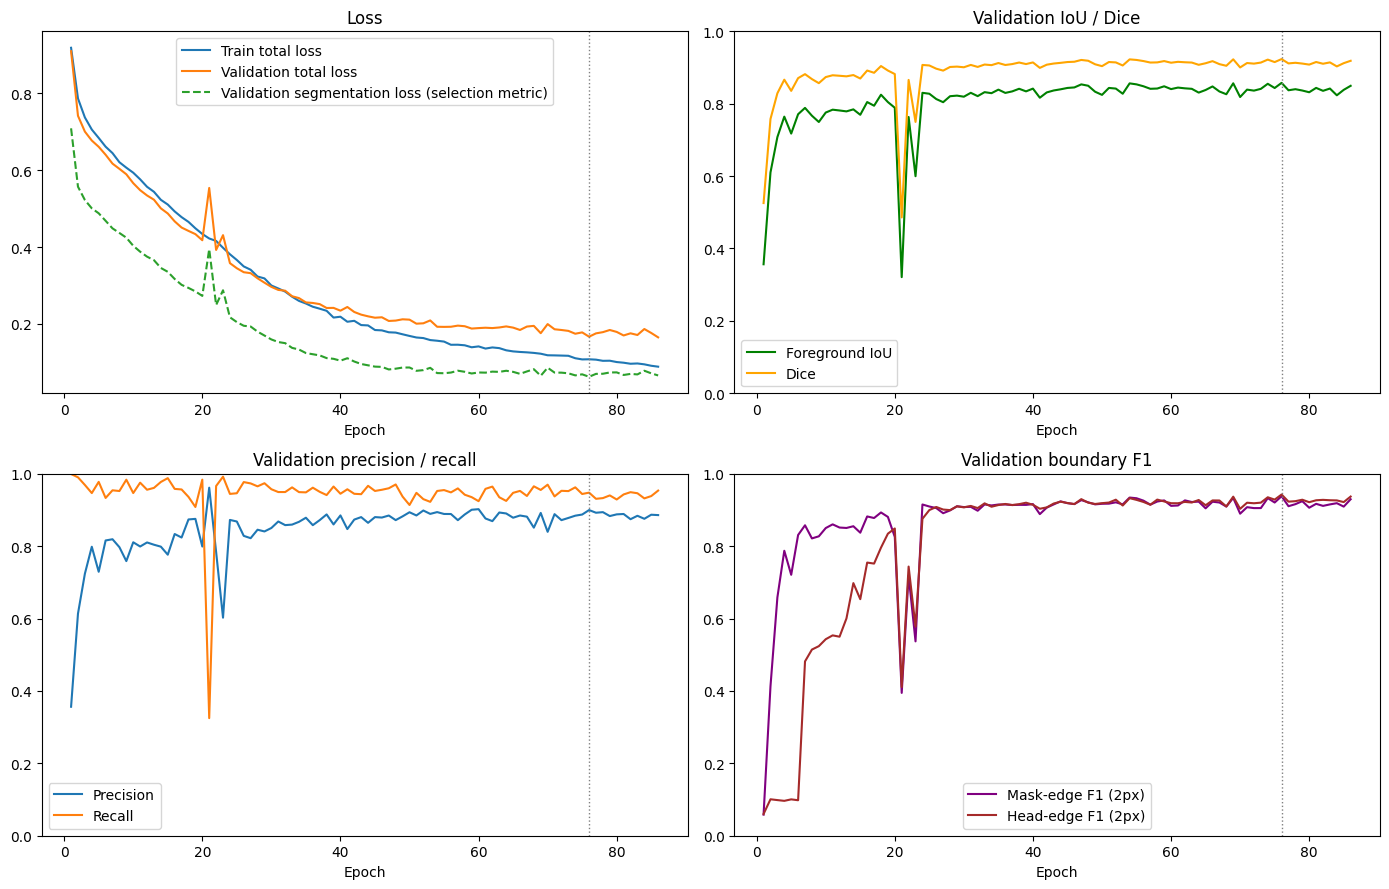

Best epoch (dotted line): 76 of 86 run


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
ep = history['epoch']
axes[0, 0].plot(ep, history['train_loss'], label='Train total loss')
axes[0, 0].plot(ep, history['val_loss'], label='Validation total loss')
axes[0, 0].plot(ep, history['val_seg_loss'], label='Validation segmentation loss (selection metric)', linestyle='--')
axes[0, 0].set_title('Loss'); axes[0, 0].legend()
axes[0, 1].plot(ep, history['val_iou'], label='Foreground IoU', color='green')
axes[0, 1].plot(ep, history['val_dice'], label='Dice', color='orange')
axes[0, 1].set_title('Validation IoU / Dice'); axes[0, 1].legend()
axes[1, 0].plot(ep, history['val_precision'], label='Precision')
axes[1, 0].plot(ep, history['val_recall'], label='Recall')
axes[1, 0].set_title('Validation precision / recall'); axes[1, 0].legend()
axes[1, 1].plot(ep, history['val_mask_edge_f1'], label='Mask-edge F1 (2px)', color='purple')
if history['val_head_edge_f1'].notna().any():
    axes[1, 1].plot(ep, history['val_head_edge_f1'], label='Head-edge F1 (2px)', color='brown')
axes[1, 1].set_title('Validation boundary F1'); axes[1, 1].legend()
for ax in axes.flat:
    ax.set_xlabel('Epoch'); ax.axvline(best_epoch, color='gray', linestyle=':', linewidth=1)
    if 'loss' not in ax.get_title().lower():
        ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(f'BSP_ResNet34UNet_{TAG}_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()
print(f"Best epoch (dotted line): {best_epoch} of {len(history)} run")

## Test evaluation


TEST - boundary_guided_attention (best epoch 76)
Total loss: 0.151314 | Segmentation loss: 0.049424 | Boundary loss: 0.509451
Foreground IoU: 0.8937 | mIoU: 0.9443 | Dice: 0.9439 | Accuracy: 0.9951
Precision: 0.9426 | Recall: 0.9451 | F1: 0.9439
Mask-edge  P/R/F1 (2px): 0.8458 / 0.9666 / 0.9022
Head-edge  P/R/F1 (2px): 0.8466 / 0.9710 / 0.9046  (nan = no boundary head)
Fragments per image  predicted: 2.92 | ground truth: 1.77 | mean |error|: 1.31 | images with extra fragments: 15%
Mean per-image IoU: 0.8817
Confusion matrix (rows = true [background, panel], columns = predicted):
[[812493   2147]
 [  2049  35279]]

VALIDATION - boundary_guided_attention (for reference)
Total loss: 0.166769 | Segmentation loss: 0.062480 | Boundary loss: 0.521444
Foreground IoU: 0.8576 | mIoU: 0.9254 | Dice: 0.9233 | Accuracy: 0.9935
Precision: 0.8999 | Recall: 0.9480 | F1: 0.9233
Mask-edge  P/R/F1 (2px): 0.9185 / 0.9587 / 0.9382
Head-edge  P/R/F1 (2px): 0.9185 / 0.9686 / 0.9429  (nan = no boundary head)

,image,iou,pred_fragments,gt_fragments,pred_px,gt_px
0,0,0.9024,1,1,3171,2909
1,1,0.9305,1,1,2341,2493
2,2,0.6867,17,2,2409,1742
3,3,0.8901,1,2,1702,1583
4,4,0.8702,2,2,3212,2795
5,5,0.9261,1,1,1294,1364
6,6,0.8150,2,1,1564,1625
7,7,0.7469,1,1,2138,2687
8,8,0.9616,3,3,5681,5763
9,9,0.9260,3,3,3212,3269


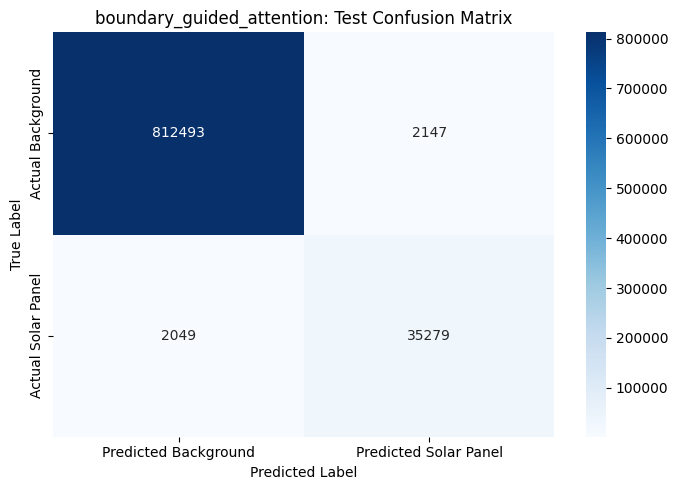


Saved results_boundary_guided_attention.json, per_image_test_boundary_guided_attention.csv, history_boundary_guided_attention.csv


In [8]:
model.load_state_dict(torch.load(CHECKPOINT, map_location=device))
model.to(device).eval()

test_metrics = validate(model, test_loader)
test_df = per_image_report(model, test_dataset)
test_frag = fragment_summary(test_df)
val_metrics = validate(model, val_loader)
val_df = per_image_report(model, val_dataset)
val_frag = fragment_summary(val_df)

def show(title, m, frag):
    print("\n" + "=" * 64); print(title); print("=" * 64)
    print(f"Total loss: {m['loss']:.6f} | Segmentation loss: {m['seg_loss']:.6f} | Boundary loss: {m['boundary_loss']:.6f}")
    print(f"Foreground IoU: {m['iou']:.4f} | mIoU: {m['miou']:.4f} | Dice: {m['dice']:.4f} | Accuracy: {m['acc']:.4f}")
    print(f"Precision: {m['precision']:.4f} | Recall: {m['recall']:.4f} | F1: {m['f1']:.4f}")
    print(f"Mask-edge  P/R/F1 (2px): {m['mask_edge_precision']:.4f} / {m['mask_edge_recall']:.4f} / {m['mask_edge_f1']:.4f}")
    print(f"Head-edge  P/R/F1 (2px): {m['head_edge_precision']:.4f} / {m['head_edge_recall']:.4f} / {m['head_edge_f1']:.4f}  (nan = no boundary head)")
    print(f"Fragments per image  predicted: {frag['mean_pred_fragments']:.2f} | ground truth: {frag['mean_gt_fragments']:.2f} | "
          f"mean |error|: {frag['mean_abs_fragment_error']:.2f} | images with extra fragments: {100 * frag['frac_images_over_fragmented']:.0f}%")
    print(f"Mean per-image IoU: {frag['mean_image_iou']:.4f}")
    print("Confusion matrix (rows = true [background, panel], columns = predicted):"); print(m['confusion'])

show(f"TEST - {TAG} (best epoch {best_epoch})", test_metrics, test_frag)
show(f"VALIDATION - {TAG} (for reference)", val_metrics, val_frag)
print("\nPer-image test results:"); display(test_df.round(4))

cm = test_metrics['confusion']
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Background', 'Predicted Solar Panel'],
            yticklabels=['Actual Background', 'Actual Solar Panel'])
plt.title(f'{TAG}: Test Confusion Matrix'); plt.ylabel('True Label'); plt.xlabel('Predicted Label')
plt.tight_layout(); plt.savefig(f'BSP_ResNet34UNet_{TAG}_confusion_matrix.png', dpi=300, bbox_inches='tight'); plt.show()

# ---- save everything needed to compare notebooks later
def _f(x):
    x = float(x)
    return None if np.isnan(x) else x
results = {'tag': TAG, 'best_epoch': int(best_epoch), 'epochs_run': int(len(history)),
           'parameters': int(sum(p.numel() for p in model.parameters())),
           'test': {k: _f(v) for k, v in test_metrics.items() if k != 'confusion'},
           'test_fragments': {k: _f(v) for k, v in test_frag.items()},
           'val': {k: _f(v) for k, v in val_metrics.items() if k != 'confusion'},
           'val_fragments': {k: _f(v) for k, v in val_frag.items()},
           'test_confusion': cm.tolist()}
json.dump(results, open(f'results_{TAG}.json', 'w'), indent=2)
test_df.to_csv(f'per_image_test_{TAG}.csv', index=False)
print(f"\nSaved results_{TAG}.json, per_image_test_{TAG}.csv, {HISTORY_CSV}")

## Visualize predictions

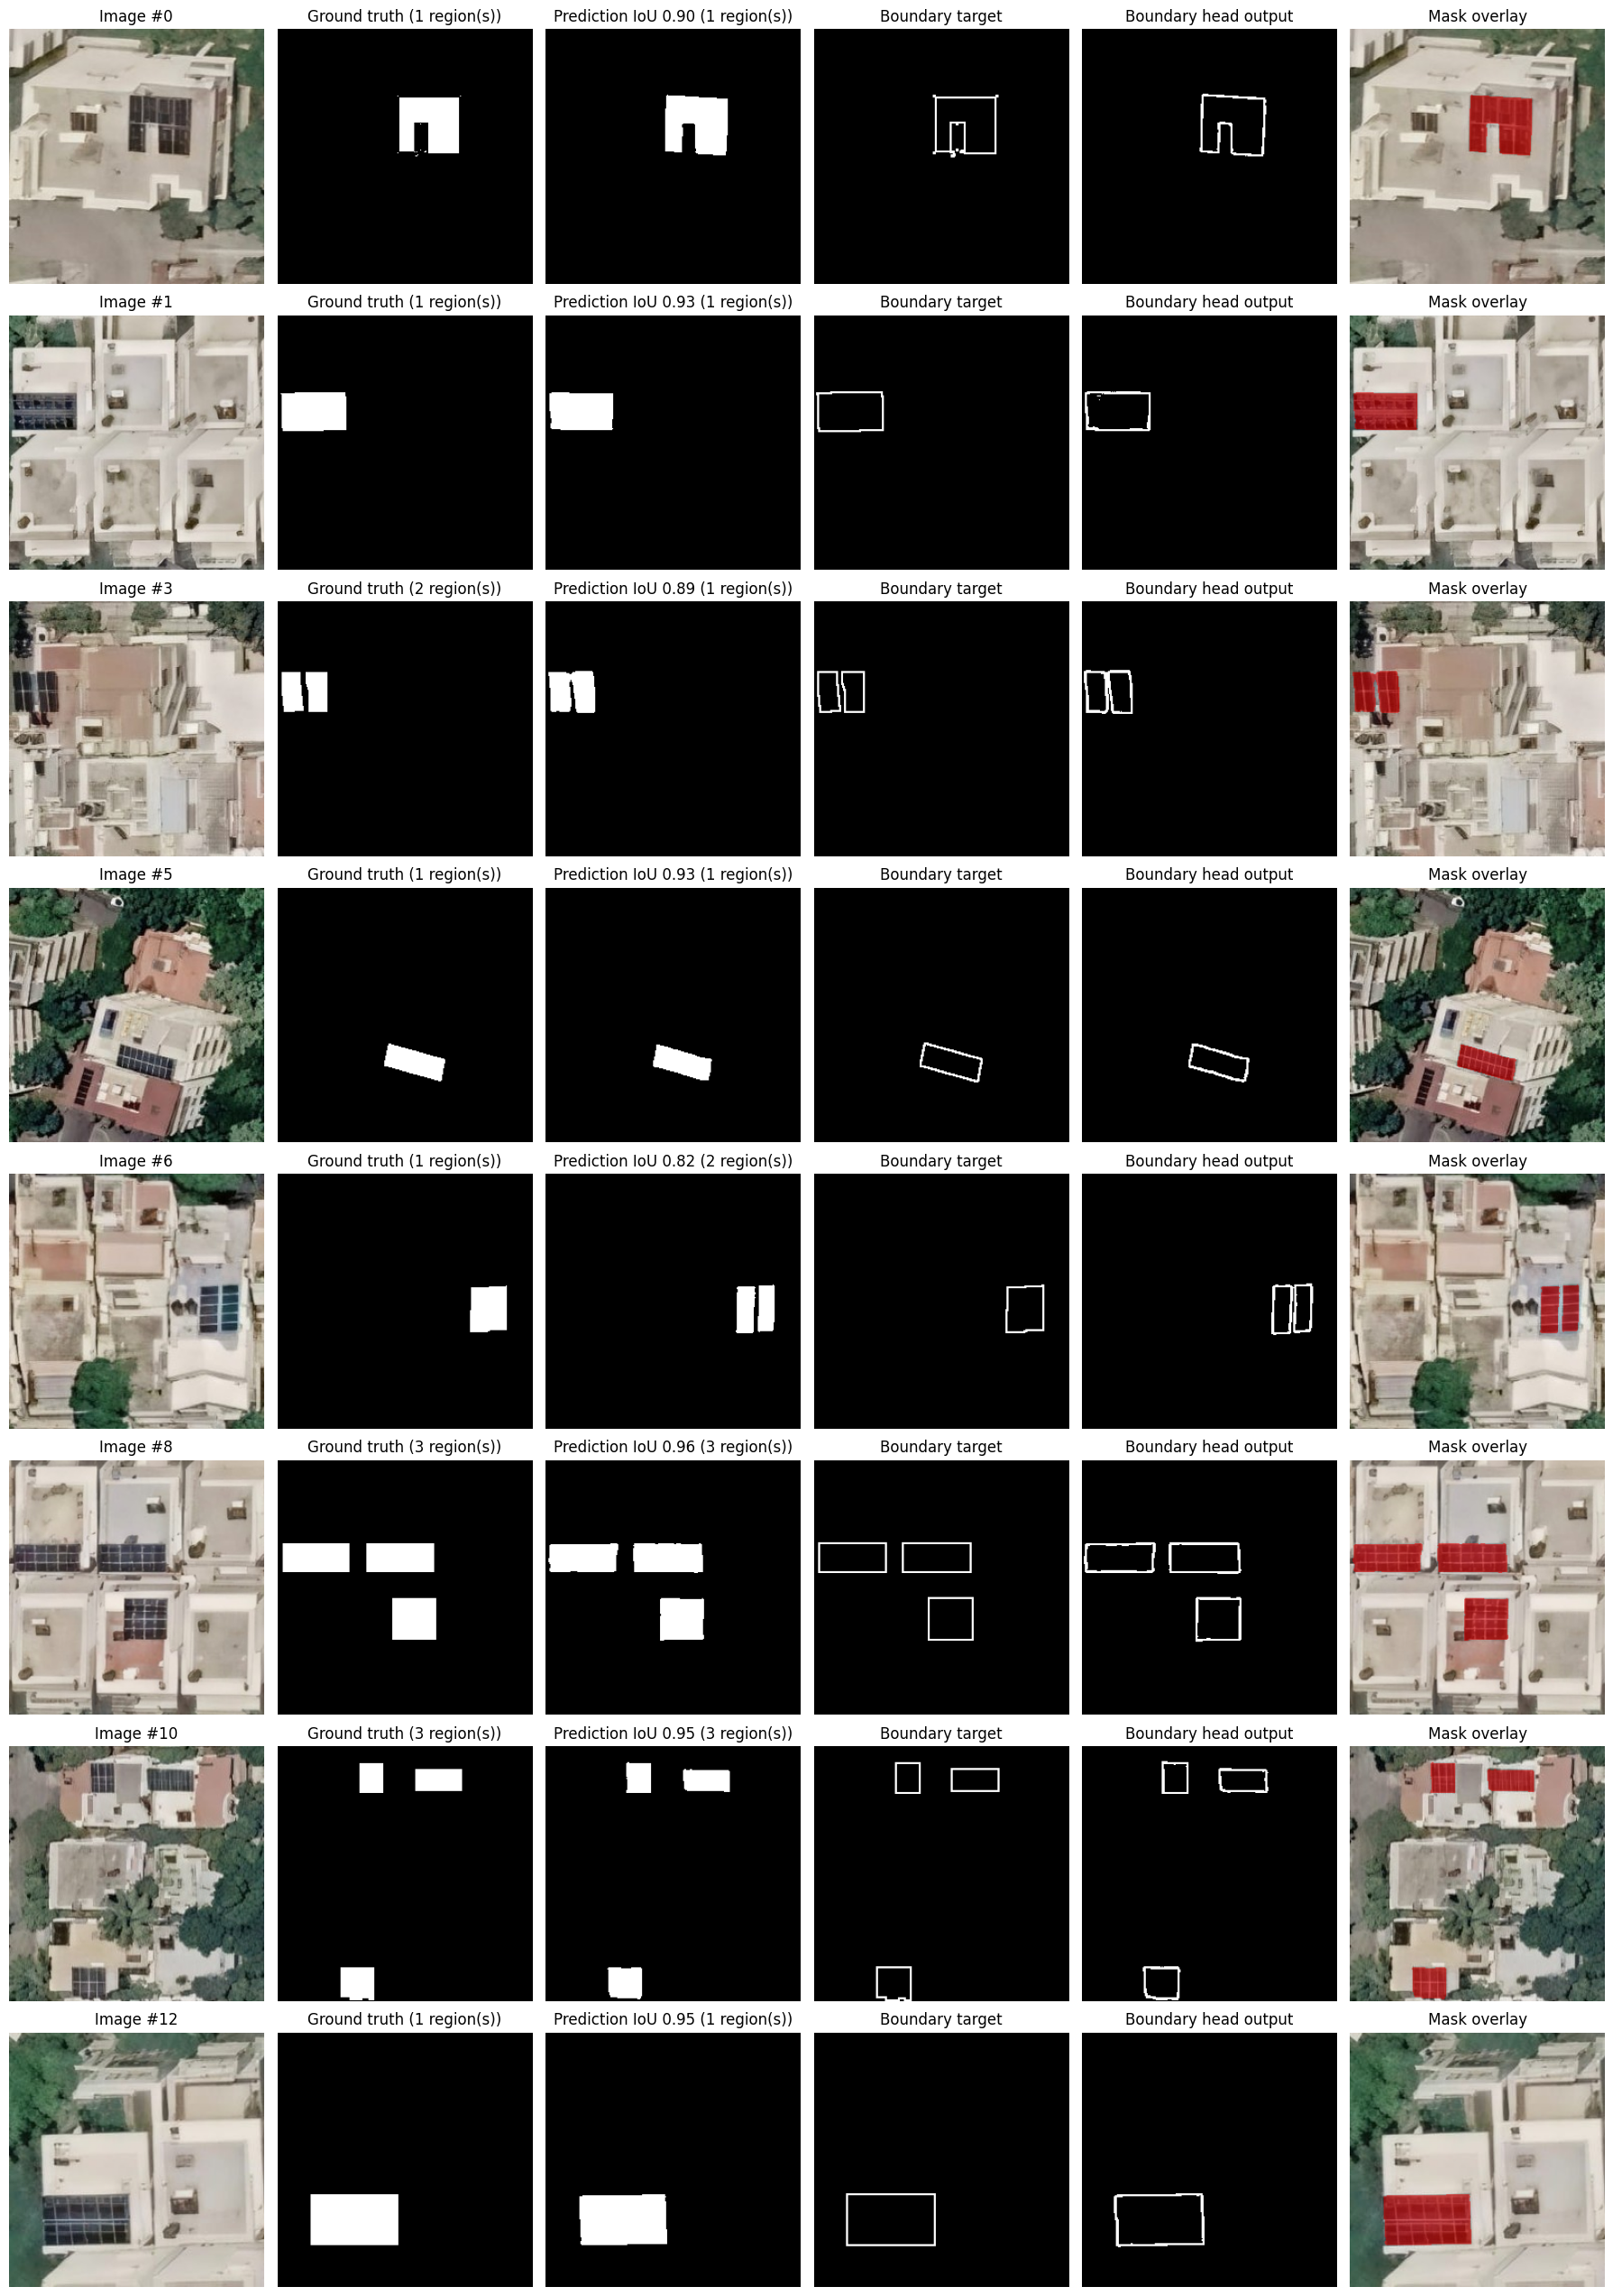

In [9]:
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def show_predictions(n=8, threshold=0.5):
    # evenly spaced test images, so every notebook shows the same ones
    indices = sorted(set(np.linspace(0, len(test_dataset) - 1, min(n, len(test_dataset))).astype(int).tolist()))
    fig, axes = plt.subplots(len(indices), 6, figsize=(18, 3.2 * len(indices)))
    if len(indices) == 1:
        axes = axes[None, :]
    for row, idx in enumerate(indices):
        image, gt = test_dataset[idx]
        with torch.no_grad():
            seg_logits, boundary_logits = model(image.unsqueeze(0).to(device))
            pred = (torch.sigmoid(seg_logits)[0, 0].cpu() >= threshold).float()
            if boundary_logits is not None:
                pred_boundary = (torch.sigmoid(boundary_logits)[0, 0].cpu() >= threshold).float().numpy()
                bnd_title = 'Boundary head output'
            else:
                pred_boundary = boundary_target_from_mask(pred[None, None])[0, 0].numpy()
                bnd_title = 'Edge of predicted mask'
        gt_np, pred_np = gt[0].numpy(), pred.numpy()
        gt_boundary = boundary_target_from_mask(gt.unsqueeze(0))[0, 0].numpy()
        rgb = (image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
        inter = (gt_np * pred_np).sum(); union = gt_np.sum() + pred_np.sum() - inter
        iou = inter / union if union > 0 else float('nan')
        fp_, fg_ = count_components(pred_np.astype(np.uint8)), count_components(gt_np.astype(np.uint8))
        overlay = rgb.copy()
        overlay[pred_np > 0] = 0.5 * overlay[pred_np > 0] + 0.5 * np.array([1, 0, 0])
        axes[row, 0].imshow(rgb); axes[row, 0].set_title(f'Image #{idx}')
        axes[row, 1].imshow(gt_np, cmap='gray'); axes[row, 1].set_title(f'Ground truth ({fg_} region(s))')
        axes[row, 2].imshow(pred_np, cmap='gray'); axes[row, 2].set_title(f'Prediction IoU {iou:.2f} ({fp_} region(s))')
        axes[row, 3].imshow(gt_boundary, cmap='gray'); axes[row, 3].set_title('Boundary target')
        axes[row, 4].imshow(pred_boundary, cmap='gray'); axes[row, 4].set_title(bnd_title)
        axes[row, 5].imshow(overlay); axes[row, 5].set_title('Mask overlay')
        for ax in axes[row]:
            ax.axis('off')
    plt.tight_layout()
    plt.savefig(f'BSP_ResNet34UNet_{TAG}_predictions.png', dpi=200, bbox_inches='tight')
    plt.show()

show_predictions(n=8)